In [1]:
import numpy as np
from matplotlib.image import imread
import matplotlib.pyplot as plt

In [2]:
image_raw = imread("image.jpg")
print(image_raw.shape)

image_sum = image_raw.sum(axis=2)
print(image_sum.shape)
image_bw = image_sum/image_sum.max()
print(image_bw.max())


(452, 678, 3)
(452, 678)
1.0


In [3]:
print(image_bw)

[[0.05359477 0.01437908 0.0379085  ... 0.09411765 0.09019608 0.08235294]
 [0.11633987 0.04183007 0.02222222 ... 0.12941176 0.14117647 0.2       ]
 [0.19869281 0.10065359 0.01830065 ... 0.12941176 0.11372549 0.2       ]
 ...
 [0.11372549 0.17647059 0.16862745 ... 0.04313725 0.04313725 0.03921569]
 [0.03921569 0.09803922 0.06666667 ... 0.04313725 0.03921569 0.03921569]
 [0.00784314 0.         0.         ... 0.03921569 0.03921569 0.03921569]]


In [4]:
mean = image_bw.mean(axis=0)
centered = image_bw - mean


In [5]:
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(centered, rowvar=False))
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

In [6]:
np.cov(centered, rowvar=False)

array([[0.01509405, 0.01475183, 0.01440518, ..., 0.00212458, 0.00185941,
        0.00159602],
       [0.01475183, 0.01570951, 0.01491523, ..., 0.0022685 , 0.00198486,
        0.0018465 ],
       [0.01440518, 0.01491523, 0.01536094, ..., 0.00196517, 0.00162107,
        0.00138728],
       ...,
       [0.00212458, 0.0022685 , 0.00196517, ..., 0.00626934, 0.00540201,
        0.00428223],
       [0.00185941, 0.00198486, 0.00162107, ..., 0.00540201, 0.00652934,
        0.00536381],
       [0.00159602, 0.0018465 , 0.00138728, ..., 0.00428223, 0.00536381,
        0.00586249]], shape=(678, 678))

In [7]:
PRECISION_CONST = 0.93
K_CONST = 40

In [8]:
cumulative = np.cumsum(eigenvalues) / eigenvalues.sum()
k = np.argmax(cumulative >= PRECISION_CONST) + 1
if (K_CONST != -1):
    k = K_CONST
print("Components for {PRECISION_CONST}% variance:", k)

Components for {PRECISION_CONST}% variance: 40


In [9]:
print(cumulative.shape)
#print(cumulative.round(3))

(678,)


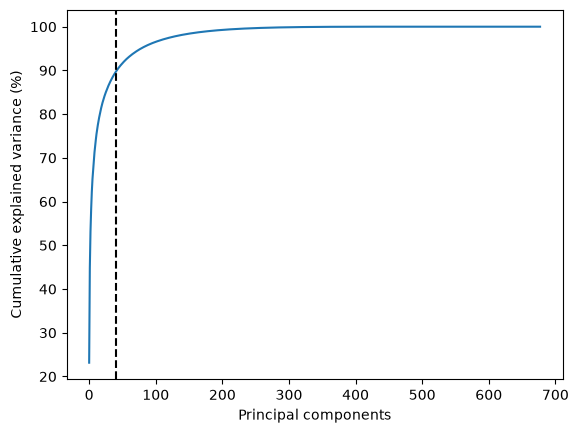

In [10]:
plt.figure()
plt.plot(cumulative * 100)
if (K_CONST == -1):plt.axhline(PRECISION_CONST * 100, color="red", linestyle="--")
plt.axvline(k, color="black", linestyle="--")
plt.xlabel("Principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.show()

In [11]:
W = eigenvectors[:, :k]
gray = np.full((cumulative.shape[0], cumulative.shape[0]), 0.5)
reconstructed = (centered @ W) @ W.T + mean
#reconstructed = (gray @ W) @ W.T + mean

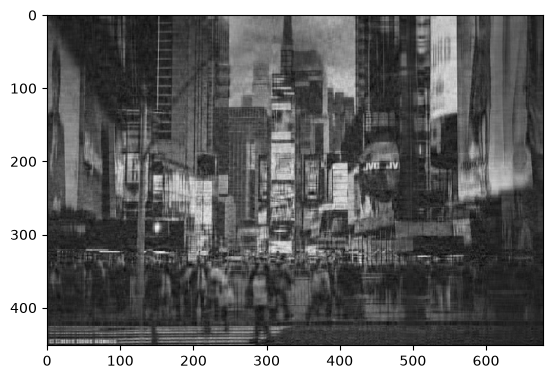

In [12]:
plt.figure()
plt.imshow(reconstructed, cmap="gray")
plt.show()